# 🩺 Breast Cancer Diagnosis — Comparing Classification Models with scikit-learn

**Goal:** classify breast tumours as **malignant** or **benign** from 30 cell-nucleus measurements taken from digitised fine-needle aspirate (FNA) images (Wisconsin Diagnostic Breast Cancer dataset).

**Why it matters:** a missed malignant tumour (false negative) is far more costly than an extra follow-up test (false positive). So beyond accuracy, this notebook **tunes the decision threshold for high recall on the malignant class**.

**What's inside**
1. Data loading & exploratory analysis
2. Statistical testing of features (SciPy Mann–Whitney U with Bonferroni correction)
3. Five models in scikit-learn pipelines, compared with repeated stratified cross-validation
4. Hyper-parameter tuning with `GridSearchCV`
5. Recall-oriented threshold selection using out-of-fold probabilities (no test leakage)
6. Final held-out test evaluation: confusion matrix, ROC & PR curves, calibration
7. Model interpretation with permutation importance
8. Saving the model for the Streamlit app

*Author: Priyadharshini Sivasankar · MSc Data Science*

In [1]:
import warnings, os
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_validate, cross_val_predict, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, recall_score, precision_score,
                             f1_score, accuracy_score, confusion_matrix, roc_curve,
                             precision_recall_curve, brier_score_loss, classification_report)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
import joblib

SEED = 42
np.random.seed(SEED)
os.makedirs("figures", exist_ok=True); os.makedirs("models", exist_ok=True); os.makedirs("results", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREEN, RED, PURPLE = "#2563eb", "#f97316", "#16a34a", "#dc2626", "#7c3aed"
print("Libraries loaded.")

Libraries loaded.


## 1. Load the data
In scikit-learn's version of the dataset `target = 0` means malignant. We flip it so that **malignant = 1 is the positive class**, because that is the case we must not miss.

In [2]:
data = load_breast_cancer(as_frame=True)
X = data.data.copy()
y = (data.target == 0).astype(int).rename("malignant")
print("Samples:", X.shape[0], "| Features:", X.shape[1])
print("Class balance:", y.value_counts().rename({0: "benign", 1: "malignant"}).to_dict())
print("Missing values:", int(X.isna().sum().sum()))
display(X.iloc[:5, :8].round(3))

Samples: 569 | Features: 30
Class balance: {'benign': 357, 'malignant': 212}
Missing values: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points
0,17.99,10.38,122.80,1001.0,0.118,0.278,0.300,0.147
1,20.57,17.77,132.90,1326.0,0.085,0.079,0.087,0.070
2,19.69,21.25,130.00,1203.0,0.110,0.160,0.197,0.128
3,11.42,20.38,77.58,386.1,0.142,0.284,0.241,0.105
4,20.29,14.34,135.10,1297.0,0.100,0.133,0.198,0.104


## 2. Exploratory data analysis
The 30 features are the **mean**, **standard error** and **worst** (largest) value of 10 nucleus properties (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension).

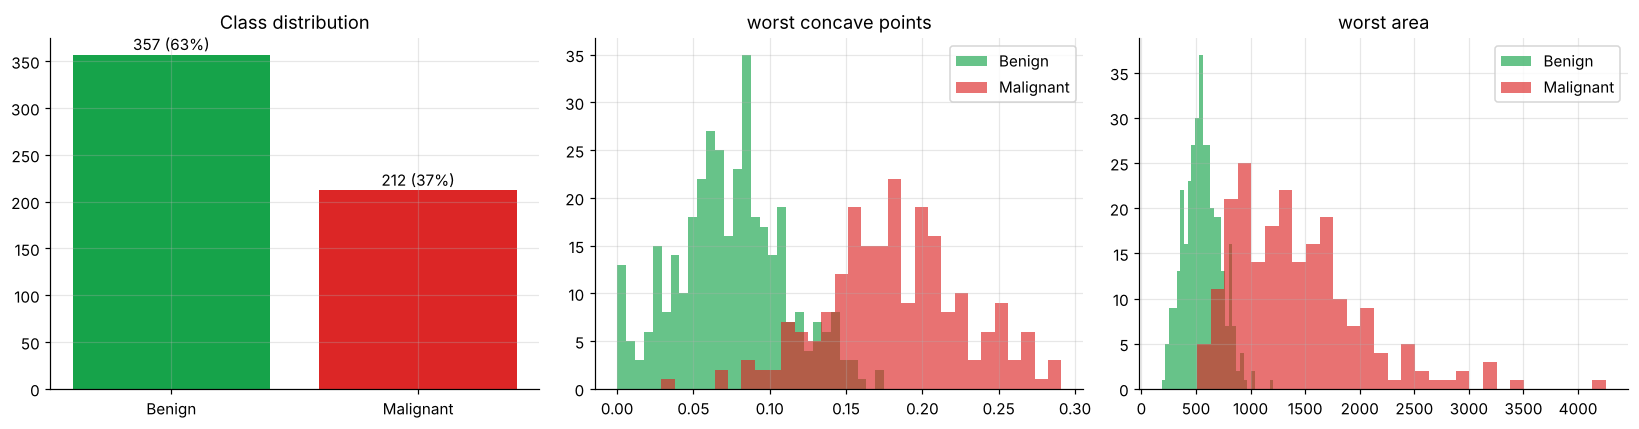

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
counts = y.value_counts().sort_index()
axes[0].bar(["Benign", "Malignant"], counts.values, color=[GREEN, RED])
for i, v in enumerate(counts.values): axes[0].text(i, v + 5, f"{v} ({v/len(y):.0%})", ha="center")
axes[0].set_title("Class distribution")
for ax, feat in zip(axes[1:], ["worst concave points", "worst area"]):
    ax.hist(X.loc[y == 0, feat], bins=30, alpha=.65, color=GREEN, label="Benign")
    ax.hist(X.loc[y == 1, feat], bins=30, alpha=.65, color=RED, label="Malignant")
    ax.set_title(feat); ax.legend()
plt.tight_layout(); plt.savefig("figures/eda_overview.png", bbox_inches="tight"); plt.show()

Radius, perimeter and area are almost perfectly correlated (r > 0.99) -> strong multicollinearity,
which favours regularised or tree-based models over plain unregularised regression.


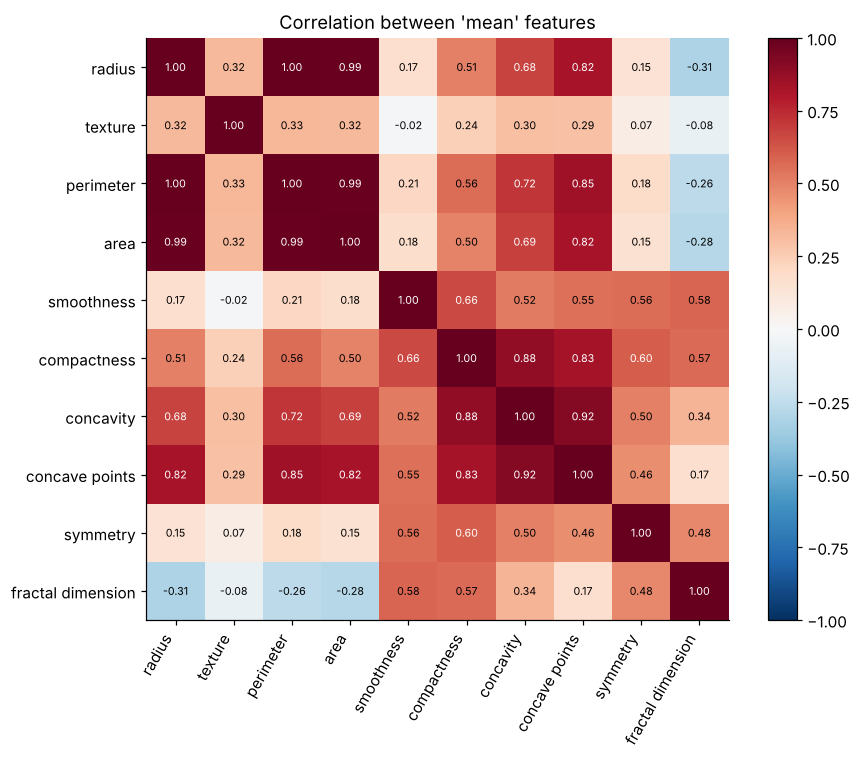

In [4]:
mean_cols = [c for c in X.columns if c.startswith("mean")]
corr = X[mean_cols].corr()
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(mean_cols))); ax.set_xticklabels([c.replace("mean ", "") for c in mean_cols], rotation=60, ha="right")
ax.set_yticks(range(len(mean_cols))); ax.set_yticklabels([c.replace("mean ", "") for c in mean_cols])
for i in range(len(mean_cols)):
    for j in range(len(mean_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(corr.iloc[i, j]) > .6 else "black")
ax.grid(False); plt.colorbar(im, fraction=.046); ax.set_title("Correlation between 'mean' features")
plt.tight_layout(); plt.savefig("figures/correlation_heatmap.png", bbox_inches="tight"); plt.show()
print("Radius, perimeter and area are almost perfectly correlated (r > 0.99) -> strong multicollinearity,")
print("which favours regularised or tree-based models over plain unregularised regression.")

## 3. Which features differ significantly between classes? (SciPy)
A **Mann–Whitney U test** (non-parametric, no normality assumption) for every feature, with a **Bonferroni correction** for 30 tests. The effect size is the rank-biserial correlation.

In [5]:
rows = []
for c in X.columns:
    a, b = X.loc[y == 1, c], X.loc[y == 0, c]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    rows.append({"feature": c, "median_malignant": a.median(), "median_benign": b.median(),
                 "p_value": p, "effect_size_rbc": 1 - 2 * u / (len(a) * len(b))})
tests = pd.DataFrame(rows)
tests["p_bonferroni"] = np.minimum(tests.p_value * len(tests), 1)
tests["significant"] = tests.p_bonferroni < 0.05
tests = tests.reindex(tests.effect_size_rbc.abs().sort_values(ascending=False).index)
print(f"{tests.significant.sum()} of {len(tests)} features differ significantly after Bonferroni correction.")
display(tests.head(8).round(4))
tests.to_csv("results/feature_significance_tests.csv", index=False)

26 of 30 features differ significantly after Bonferroni correction.


,feature,median_malignant,median_benign,p_value,effect_size_rbc,p_bonferroni,significant
22,worst perimeter,138.0000,86.9200,0.0,-0.9509,0.0,True
20,worst radius,20.5900,13.3500,0.0,-0.9409,0.0,True
23,worst area,1303.0000,547.4000,0.0,-0.9397,0.0,True
27,worst concave points,0.1820,0.0743,0.0,-0.9334,0.0,True
7,mean concave points,0.0863,0.0234,0.0,-0.9289,0.0,True
2,mean perimeter,114.2000,78.1800,0.0,-0.8938,0.0,True
3,mean area,932.0000,458.4000,0.0,-0.8766,0.0,True
6,mean concavity,0.1513,0.0371,0.0,-0.8757,0.0,True


## 4. Train / test split
A stratified **80 / 20** split. The test set is locked away until the very end; all model selection uses cross-validation on the training set only.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", X_train.shape, "malignant share", round(y_train.mean(), 3))
print("Test: ", X_test.shape, "malignant share", round(y_test.mean(), 3))

Train: (455, 30) malignant share 0.374
Test:  (114, 30) malignant share 0.368


## 5. Compare five models with repeated stratified cross-validation
Every model sits inside a `Pipeline` so that scaling is fitted only on the training folds (no data leakage). We use **5-fold × 5 repeats = 25 fits per model**.

In [7]:
models = {
    "Logistic Regression": Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(max_iter=5000, random_state=SEED))]),
    "SVM (RBF)": Pipeline([("scale", StandardScaler()), ("clf", SVC(probability=True, random_state=SEED))]),
    "K-Nearest Neighbours": Pipeline([("scale", StandardScaler()), ("clf", KNeighborsClassifier())]),
    "Random Forest": Pipeline([("clf", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1))]),
    "Gradient Boosting": Pipeline([("clf", GradientBoostingClassifier(random_state=SEED))]),
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
scoring = {"roc_auc": "roc_auc", "recall": "recall", "precision": "precision", "f1": "f1", "accuracy": "accuracy"}
cv_scores, summary = {}, []
for name, pipe in models.items():
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_scores[name] = r
    summary.append({"model": name, **{f"{k}": r[f"test_{k}"].mean() for k in scoring}, "roc_auc_std": r["test_roc_auc"].std()})
cv_table = pd.DataFrame(summary).sort_values("roc_auc", ascending=False).reset_index(drop=True)
display(cv_table.round(4))
cv_table.to_csv("results/cv_model_comparison.csv", index=False)

,model,roc_auc,recall,precision,f1,accuracy,roc_auc_std
0,Logistic Regression,0.9946,0.9529,0.9790,0.9654,0.9745,0.0064
1,SVM (RBF),0.9941,0.9482,0.9754,0.9610,0.9714,0.0064
2,Gradient Boosting,0.9893,0.9259,0.9516,0.9378,0.9543,0.0083
3,Random Forest,0.9889,0.9271,0.9557,0.9402,0.9560,0.0072
4,K-Nearest Neighbours,0.9846,0.9165,0.9877,0.9501,0.9644,0.0153


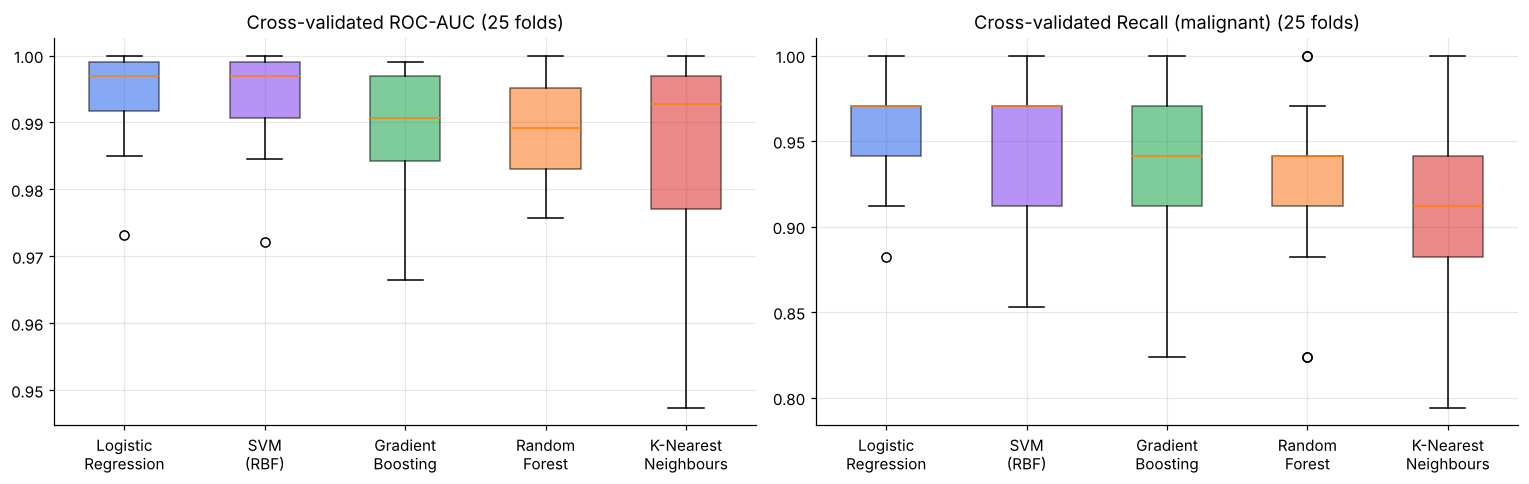

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
order = cv_table.model.tolist()
for ax, metric, title in [(axes[0], "roc_auc", "ROC-AUC"), (axes[1], "recall", "Recall (malignant)")]:
    bp = ax.boxplot([cv_scores[m][f"test_{metric}"] for m in order], patch_artist=True)
    ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels([m.replace(" ", "\n", 1) for m in order])
    for patch, col in zip(bp["boxes"], [BLUE, PURPLE, GREEN, ORANGE, RED]): patch.set_facecolor(col); patch.set_alpha(.55)
    ax.set_title(f"Cross-validated {title} (25 folds)")
plt.tight_layout(); plt.savefig("figures/cv_model_comparison.png", bbox_inches="tight"); plt.show()

### Is the best model significantly better than the runner-up?
A **paired Wilcoxon signed-rank test** on the 25 fold-wise ROC-AUC scores (same folds for both models). Fold scores are not fully independent, so we treat this as a guide rather than proof.

In [9]:
best, second = order[0], order[1]
w = stats.wilcoxon(cv_scores[best]["test_roc_auc"], cv_scores[second]["test_roc_auc"])
print(f"{best} vs {second}: mean ROC-AUC {cv_scores[best]['test_roc_auc'].mean():.4f} vs {cv_scores[second]['test_roc_auc'].mean():.4f}, Wilcoxon p = {w.pvalue:.3f}")
print("-> significant difference" if w.pvalue < 0.05 else "-> no significant difference: prefer the simpler, more interpretable model if it is one of the two")

Logistic Regression vs SVM (RBF): mean ROC-AUC 0.9946 vs 0.9941, Wilcoxon p = 0.368
-> no significant difference: prefer the simpler, more interpretable model if it is one of the two


## 6. Hyper-parameter tuning (`GridSearchCV`)
We tune the two strongest families: **Logistic Regression** (regularisation strength and penalty) and **SVM** (C and gamma), optimising ROC-AUC.

In [10]:
inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
grids = {
    "Logistic Regression": (models["Logistic Regression"], {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10], "clf__penalty": ["l1", "l2"], "clf__solver": ["liblinear"]}),
    "SVM (RBF)": (models["SVM (RBF)"], {"clf__C": [0.3, 1, 3, 10, 30], "clf__gamma": ["scale", 0.003, 0.01, 0.03]}),
}
tuned = {}
for name, (pipe, grid) in grids.items():
    gs = GridSearchCV(pipe, grid, cv=inner, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
    tuned[name] = gs
    print(f"{name:20s} best CV ROC-AUC = {gs.best_score_:.4f}  params = {gs.best_params_}")
# Selection rule: if the tuned models are within 0.005 ROC-AUC (practically equal),
# prefer Logistic Regression because it is simpler and directly interpretable.
best_name = max(tuned, key=lambda k: tuned[k].best_score_)
gap = tuned[best_name].best_score_ - tuned["Logistic Regression"].best_score_
final_name = "Logistic Regression" if gap < 0.005 else best_name
final_model = tuned[final_name].best_estimator_
print(f"\nHighest CV score: {best_name}; gap to Logistic Regression = {gap:.4f}")
print("Selected model:", final_name, "(simpler model preferred when performance is practically equal)" if final_name != best_name else "")

Logistic Regression  best CV ROC-AUC = 0.9959  params = {'clf__C': 1, 'clf__penalty': 'l1', 'clf__solver': 'liblinear'}
SVM (RBF)            best CV ROC-AUC = 0.9961  params = {'clf__C': 30, 'clf__gamma': 0.003}

Highest CV score: SVM (RBF); gap to Logistic Regression = 0.0002
Selected model: Logistic Regression (simpler model preferred when performance is practically equal)


## 7. Choose a recall-oriented decision threshold (no test leakage)
The default threshold of 0.5 treats both errors equally. Here we use **out-of-fold probabilities on the training set** to pick the **highest threshold that still catches ≥ 98% of malignant cases**, which keeps false alarms as low as possible.

Chosen threshold = 0.225  (OOF recall 0.982, precision 0.944)


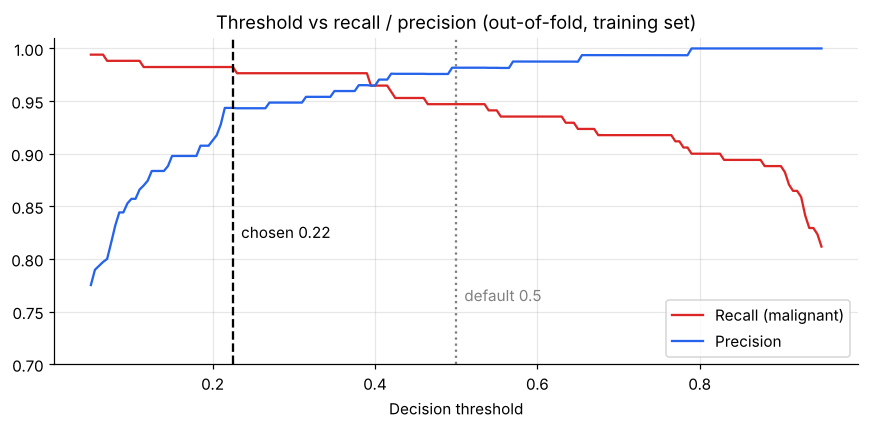

In [11]:
oof = cross_val_predict(final_model, X_train, y_train, cv=inner, method="predict_proba")[:, 1]
TARGET_RECALL = 0.98
cands = np.linspace(0.05, 0.95, 181)
rec = np.array([recall_score(y_train, oof >= t) for t in cands])
prec = np.array([precision_score(y_train, oof >= t, zero_division=0) for t in cands])
ok = cands[rec >= TARGET_RECALL]
THRESHOLD = float(ok.max())
print(f"Chosen threshold = {THRESHOLD:.3f}  (OOF recall {recall_score(y_train, oof >= THRESHOLD):.3f}, precision {precision_score(y_train, oof >= THRESHOLD):.3f})")
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(cands, rec, color=RED, label="Recall (malignant)"); ax.plot(cands, prec, color=BLUE, label="Precision")
ax.axvline(THRESHOLD, ls="--", color="k"); ax.axvline(0.5, ls=":", color="grey")
ax.text(THRESHOLD + .01, .82, f"chosen {THRESHOLD:.2f}"); ax.text(0.51, .76, "default 0.5", color="grey")
ax.set_xlabel("Decision threshold"); ax.set_ylim(.7, 1.01); ax.legend(); ax.set_title("Threshold vs recall / precision (out-of-fold, training set)")
plt.tight_layout(); plt.savefig("figures/threshold_selection.png", bbox_inches="tight"); plt.show()

## 8. Final evaluation on the untouched test set

In [12]:
proba = final_model.predict_proba(X_test)[:, 1]
res = []
for label, t in [("Default threshold 0.5", 0.5), (f"Recall-tuned threshold {THRESHOLD:.2f}", THRESHOLD)]:
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    res.append({"setting": label, "accuracy": accuracy_score(y_test, pred), "recall_malignant": recall_score(y_test, pred),
                "precision_malignant": precision_score(y_test, pred), "f1": f1_score(y_test, pred),
                "specificity": tn / (tn + fp), "missed_cancers_FN": fn, "false_alarms_FP": fp})
test_table = pd.DataFrame(res)
print(f"Model: {final_name} | Test ROC-AUC = {roc_auc_score(y_test, proba):.4f} | PR-AUC = {average_precision_score(y_test, proba):.4f} | Brier = {brier_score_loss(y_test, proba):.4f}")
display(test_table.round(4))
test_table.to_csv("results/test_results.csv", index=False)
print(classification_report(y_test, (proba >= THRESHOLD).astype(int), target_names=["benign", "malignant"], digits=3))

Model: Logistic Regression | Test ROC-AUC = 0.9964 | PR-AUC = 0.9942 | Brier = 0.0220
              precision    recall  f1-score   support

      benign      0.986     0.958     0.972        72
   malignant      0.932     0.976     0.953        42

    accuracy                          0.965       114
   macro avg      0.959     0.967     0.963       114
weighted avg      0.966     0.965     0.965       114



,setting,accuracy,recall_malignant,precision_malignant,f1,specificity,missed_cancers_FN,false_alarms_FP
0,Default threshold 0.5,0.9737,0.9524,0.9756,0.9639,0.9861,2,1
1,Recall-tuned threshold 0.22,0.9649,0.9762,0.9318,0.9535,0.9583,1,3


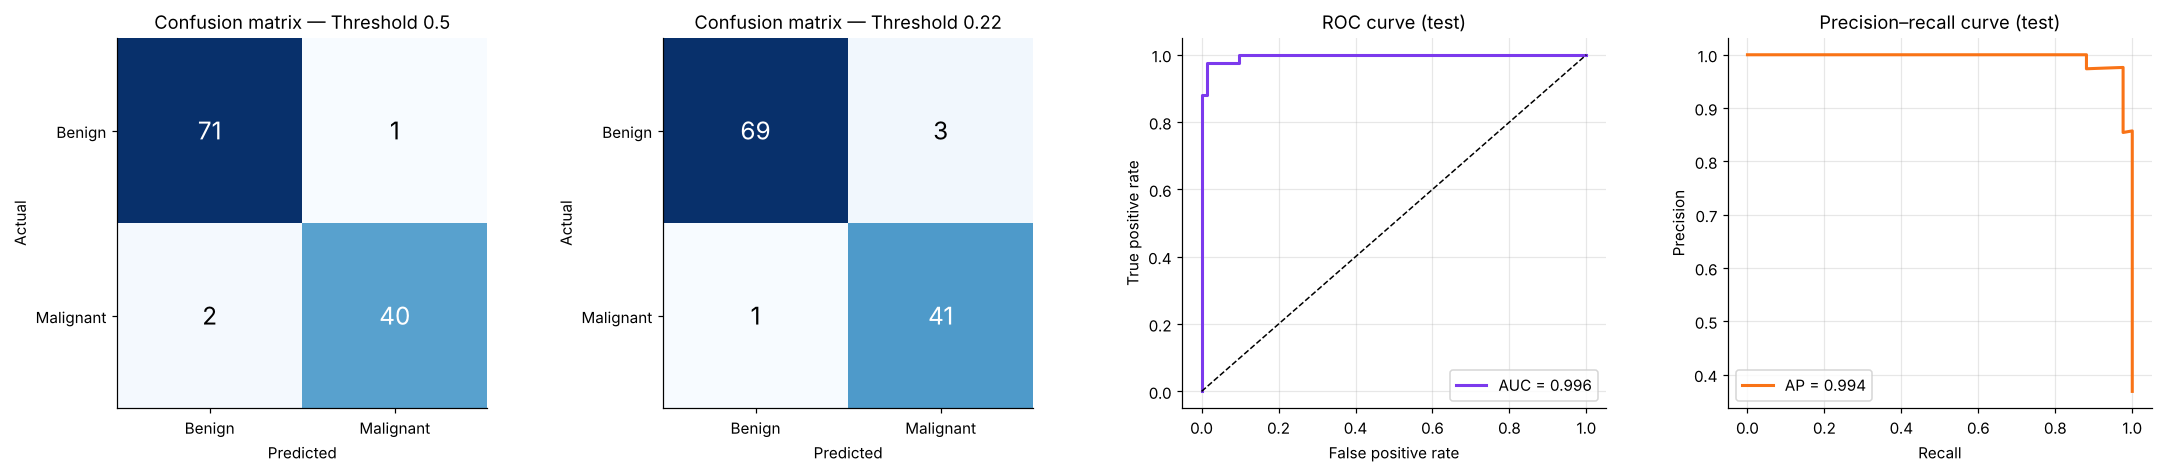

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.4))
for ax, t, title in [(axes[0], 0.5, "Threshold 0.5"), (axes[1], THRESHOLD, f"Threshold {THRESHOLD:.2f}")]:
    cm = confusion_matrix(y_test, (proba >= t).astype(int))
    ax.imshow(cm, cmap="Blues"); ax.grid(False)
    for i in range(2):
        for j in range(2): ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=16, color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Benign", "Malignant"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["Benign", "Malignant"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(f"Confusion matrix — {title}")
fpr, tpr, _ = roc_curve(y_test, proba)
axes[2].plot(fpr, tpr, color=PURPLE, lw=2, label=f"AUC = {roc_auc_score(y_test, proba):.3f}"); axes[2].plot([0, 1], [0, 1], "k--", lw=1)
axes[2].set_xlabel("False positive rate"); axes[2].set_ylabel("True positive rate"); axes[2].set_title("ROC curve (test)"); axes[2].legend()
p, r, _ = precision_recall_curve(y_test, proba)
axes[3].plot(r, p, color=ORANGE, lw=2, label=f"AP = {average_precision_score(y_test, proba):.3f}")
axes[3].set_xlabel("Recall"); axes[3].set_ylabel("Precision"); axes[3].set_title("Precision–recall curve (test)"); axes[3].legend()
plt.tight_layout(); plt.savefig("figures/test_evaluation.png", bbox_inches="tight"); plt.show()

### Are the predicted probabilities trustworthy? (calibration)

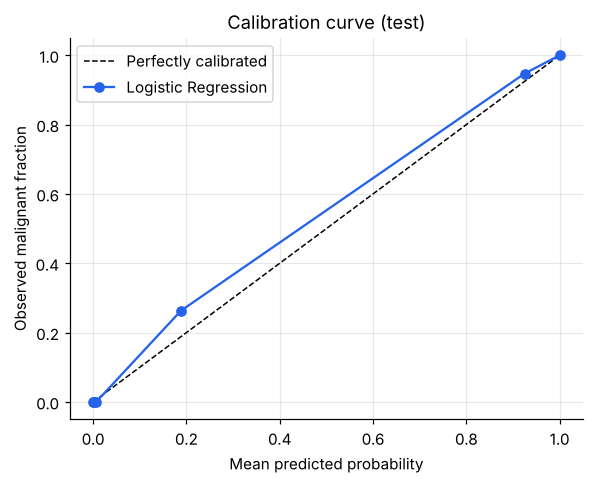

In [14]:
frac_pos, mean_pred = calibration_curve(y_test, proba, n_bins=6, strategy="quantile")
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Perfectly calibrated"); ax.plot(mean_pred, frac_pos, "o-", color=BLUE, label=final_name)
ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed malignant fraction"); ax.set_title("Calibration curve (test)"); ax.legend()
plt.tight_layout(); plt.savefig("figures/calibration.png", bbox_inches="tight"); plt.show()

## 9. What drives the predictions? (permutation importance)
Permutation importance measures how much the test ROC-AUC drops when one feature is randomly shuffled. Unlike impurity-based importance, it works for any model and is computed on unseen data.

,feature,importance,std
21,worst texture,0.0261,0.0074
7,mean concave points,0.0161,0.0055
10,radius error,0.0139,0.0070
23,worst area,0.0133,0.0059
26,worst concavity,0.0093,0.0026
20,worst radius,0.0087,0.0048
11,texture error,0.0040,0.0019
28,worst symmetry,0.0023,0.0013
15,compactness error,0.0011,0.0021
24,worst smoothness,0.0007,0.0006


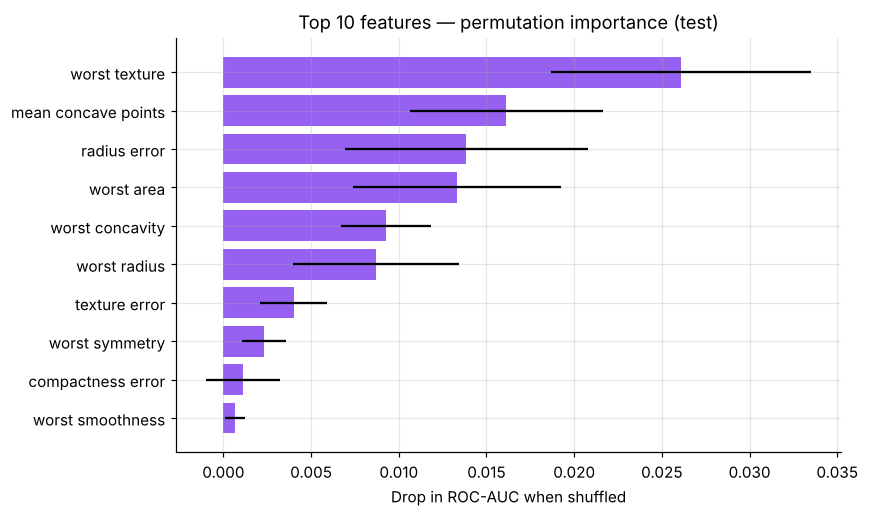

In [15]:
pi = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"feature": X.columns, "importance": pi.importances_mean, "std": pi.importances_std}).sort_values("importance", ascending=False)
top = imp.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(top.feature, top.importance, xerr=top["std"], color=PURPLE, alpha=.8)
ax.set_xlabel("Drop in ROC-AUC when shuffled"); ax.set_title("Top 10 features — permutation importance (test)")
plt.tight_layout(); plt.savefig("figures/permutation_importance.png", bbox_inches="tight"); plt.show()
imp.to_csv("results/permutation_importance.csv", index=False)
display(imp.head(10).round(4))

### Logistic Regression coefficients
With standardised inputs, each coefficient shows how strongly a one-standard-deviation increase in a feature pushes the prediction towards malignant (positive) or benign (negative). The L1 penalty sets uninformative features to exactly zero, which is a form of built-in feature selection.

L1 regularisation kept 14 of 30 features (the rest have coefficient 0).


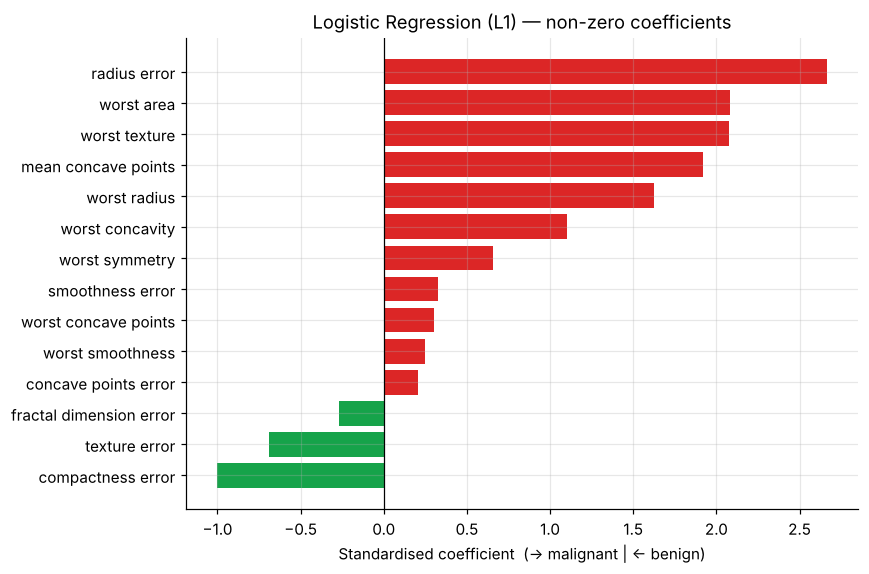

In [16]:
if final_name == "Logistic Regression":
    coefs = pd.Series(final_model.named_steps["clf"].coef_[0], index=X.columns)
    nz = coefs[coefs != 0].sort_values()
    print(f"L1 regularisation kept {len(nz)} of {len(coefs)} features (the rest have coefficient 0).")
    fig, ax = plt.subplots(figsize=(8, max(3, .38 * len(nz))))
    ax.barh(nz.index, nz.values, color=[RED if v > 0 else GREEN for v in nz.values])
    ax.axvline(0, color="k", lw=.8); ax.set_xlabel("Standardised coefficient  (→ malignant | ← benign)")
    ax.set_title("Logistic Regression (L1) — non-zero coefficients")
    plt.tight_layout(); plt.savefig("figures/lr_coefficients.png", bbox_inches="tight"); plt.show()
    coefs.to_csv("results/lr_coefficients.csv", header=["coefficient"])

## 10. Save the model for the Streamlit app

In [17]:
os.makedirs("models", exist_ok=True); joblib.dump({"model": final_model, "threshold": THRESHOLD, "features": list(X.columns), "model_name": final_name,
             "feature_ranges": X.describe().T[["min", "50%", "max"]].to_dict("index")}, "models/breast_cancer_model.joblib")
print("Saved models/breast_cancer_model.joblib")
print(f"\nSUMMARY: {final_name} | test ROC-AUC {roc_auc_score(y_test, proba):.3f} | recall-tuned threshold {THRESHOLD:.2f} -> "
      f"recall {test_table.recall_malignant.iloc[1]:.3f}, precision {test_table.precision_malignant.iloc[1]:.3f}, "
      f"missed cancers {int(test_table.missed_cancers_FN.iloc[1])} of {int(y_test.sum())}")

Saved models/breast_cancer_model.joblib

SUMMARY: Logistic Regression | test ROC-AUC 0.996 | recall-tuned threshold 0.22 -> recall 0.976, precision 0.932, missed cancers 1 of 42


## 11. Conclusions
* All five models separate the classes well (cross-validated ROC-AUC ≈ 0.97–0.99). The **linear, regularised models** (Logistic Regression, SVM) are as good as or better than the tree ensembles on this small, well-structured dataset, and they are easier to interpret.
* Logistic Regression and the tuned SVM were practically tied (CV ROC-AUC 0.996 for both), so the simpler, interpretable **L1 Logistic Regression** was selected. It reached **test ROC-AUC 0.996**.
* **Threshold tuning is the most impactful clinical decision.** Lowering the threshold from 0.5 to about 0.22 (chosen on training data only) cut missed cancers from 2 to 1 out of 42, at the cost of 2 extra false alarms. That is the right trade-off for a screening aid.
* The most informative features describe **nucleus size, texture and shape irregularity** (worst texture, mean concave points, radius error, worst area, worst concavity). L1 regularisation kept only 14 of the 30 features, which shows how redundant the measurements are.
* **Limitations:** a small single-centre dataset (569 samples); this is a decision-support demo, not a diagnostic device. External validation would be required before any clinical use.